# Football Player Roles: Cross-Validation and Model Tuning
**Week 4 | Fayz Liaqat | 31 October 2026**

Can age, physical measurements, preferred foot, and FIFA skill ratings
distinguish defenders, midfielders, and forwards?

I use Argentina's male players from the
[FIFA 22 dataset](https://www.kaggle.com/datasets/stefanoleone992/fifa-22-complete-player-dataset).
This includes Messi, whose first listed position is RW. The target is a
role group derived from the **first listed position**, not a player rating.
Goalkeepers are excluded because their ratings describe a different role.

I compare KNN, Decision Tree, Random Forest, and Gradient Boosting using
five-fold cross-validation. All preprocessing and tuning use training data
only. The final 20% test set stays untouched until Step 6.

These are historical video-game ratings. The results describe this FIFA 22
cohort and do not establish real-world scouting ability or match performance.

## Step 1: Prepare the data
The included file contains 960 Argentina players and 14 relevant columns
from the original 19,239-player snapshot. I check missing values and
duplicates, keep one row per player, and remove goalkeepers. No missing
values are artificially added.

I use an explicit input list. Names, IDs, nationality, and position strings
cannot enter the model. Position-specific ratings and overall ratings are
also excluded, so the answer is not handed to the model through another
position column. Every retained first-position code must map to one role.

Included dataset shape: (960, 14)


,sofifa_id,short_name,nationality_name,player_positions,age,height_cm,weight_kg,preferred_foot,pace,shooting,passing,dribbling,defending,physic
0,158023,L. Messi,Argentina,"RW, ST, CF",34,170,72,Left,85.0,92.0,91.0,95.0,34.0,65.0
1,153079,S. Agüero,Argentina,ST,33,173,70,Right,71.0,89.0,75.0,87.0,33.0,69.0
2,183898,Á. Di María,Argentina,"RW, LW",33,180,69,Left,83.0,81.0,86.0,87.0,48.0,69.0
3,211110,P. Dybala,Argentina,"CF, CAM",27,177,75,Left,84.0,86.0,86.0,90.0,40.0,60.0
4,143076,A. Gómez,Argentina,"CAM, CF, CM",33,167,68,Right,87.0,78.0,84.0,87.0,39.0,55.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 960 entries, 0 to 959
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sofifa_id         960 non-null    int64  
 1   short_name        960 non-null    object 
 2   nationality_name  960 non-null    object 
 3   player_positions  960 non-null    object 
 4   age               960 non-null    int64  
 5   height_cm         960 non-null    int64  
 6   weight_kg         960 non-null    int64  
 7   preferred_foot    960 non-null    object 
 8   pace              864 non-null    float64
 9   shooting          864 non-null    float64
 10  passing           864 non-null    float64
 11  dribbling         864 non-null    float64
 12  defending         864 non-null    float64
 13  physic            864 non-null    float64
dtypes: float64(6), int64(4), object(4)
memory usage: 105.1+ KB


,missingCount
sofifa_id,0
short_name,0
nationality_name,0
player_positions,0
age,0
height_cm,0
weight_kg,0
preferred_foot,0
pace,96
shooting,96


Exact duplicate rows: 0
Repeated player IDs: 0
Goalkeepers excluded: 96
Outfield players: 864


,missingCount
age,0
heightCm,0
weightKg,0
preferredFoot,0
pace,0
shooting,0
passing,0
dribbling,0
defending,0
physic,0


,count,mean,std,min,25%,50%,75%,max
age,864.0,26.297454,5.110659,16.0,22.0,26.0,30.0,40.0
heightCm,864.0,178.127315,6.490388,156.0,174.0,178.0,183.0,197.0
weightKg,864.0,73.781250,6.505338,56.0,70.0,73.0,78.0,97.0
pace,864.0,68.105324,11.190824,31.0,63.0,69.0,76.0,91.0
shooting,864.0,56.179398,13.628373,23.0,47.0,59.0,67.0,92.0
passing,864.0,60.194444,9.436703,29.0,54.0,61.0,67.0,91.0
dribbling,864.0,65.685185,9.073689,31.0,61.0,67.0,71.0,95.0
defending,864.0,52.722222,16.065240,21.0,37.0,58.0,66.0,83.0
physic,864.0,66.077546,9.672254,37.0,60.0,67.0,73.0,86.0


,count,percent
role,,
Defender,285,32.99
Midfielder,372,43.06
Forward,207,23.96


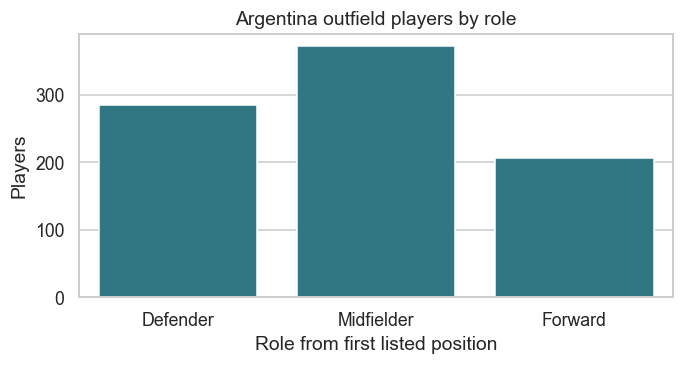

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

projectDir = Path.cwd()
outputDir = projectDir / "outputs"
outputDir.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110

playerData = pd.read_csv(projectDir / "data" / "argentina_players_22.csv")
print("Included dataset shape:", playerData.shape)
display(playerData.head())
playerData.info()
display(playerData.isna().sum().rename("missingCount").to_frame())
print("Exact duplicate rows:", playerData.duplicated().sum())
print("Repeated player IDs:", playerData["sofifa_id"].duplicated().sum())
playerData = playerData.drop_duplicates().drop_duplicates(subset="sofifa_id").copy()
playerData = playerData.dropna(subset=["player_positions"]).copy()
playerData["firstPosition"] = playerData["player_positions"].str.split(",").str[0].str.strip()
print("Goalkeepers excluded:", playerData["firstPosition"].eq("GK").sum())
playerData = playerData[playerData["firstPosition"] != "GK"].copy()

positionGroups = {
    "CB": "Defender", "LB": "Defender", "RB": "Defender",
    "LWB": "Defender", "RWB": "Defender",
    "CDM": "Midfielder", "CM": "Midfielder", "CAM": "Midfielder",
    "LM": "Midfielder", "RM": "Midfielder",
    "ST": "Forward", "CF": "Forward", "LW": "Forward", "RW": "Forward"
}
playerData["role"] = playerData["firstPosition"].map(positionGroups)
assert playerData["role"].notna().all()
assert playerData["sofifa_id"].is_unique

featureColumns = [
    "age", "height_cm", "weight_kg", "preferred_foot",
    "pace", "shooting", "passing", "dribbling", "defending", "physic"
]
features = playerData[featureColumns].rename(columns={
    "height_cm": "heightCm", "weight_kg": "weightKg", "preferred_foot": "preferredFoot"
})
target = playerData["role"]
print("Outfield players:", len(playerData))
display(features.isna().sum().rename("missingCount").to_frame())
display(features.describe().T)

classOrder = ["Defender", "Midfielder", "Forward"]
classBalance = pd.DataFrame({
    "count": target.value_counts().reindex(classOrder),
    "percent": target.value_counts(normalize=True).reindex(classOrder).mul(100).round(2)
})
display(classBalance)
classBalance.to_csv(outputDir / "class_balance.csv", index_label="role")

plt.figure(figsize=(6.4, 3.5))
sns.countplot(x=target, order=classOrder, color="#237F91")
plt.title("Argentina outfield players by role")
plt.xlabel("Role from first listed position")
plt.ylabel("Players")
plt.tight_layout()
plt.savefig(outputDir / "class_balance.png", dpi=180)
plt.show()
plt.close()

### Split once and keep preprocessing inside each fold
I use an 80/20 split with `stratify=target` and `random_state=42`.
Every comparison uses the same shuffled `StratifiedKFold` with five folds.

There are no missing input values in this outfield cohort, but the pipelines
still handle gaps: median filling for numbers and mode filling for text.
Preferred foot is one-hot encoded. KNN then uses `StandardScaler` on the
encoded inputs so feature magnitudes do not dominate distances.

The pipelines are passed directly to cross-validation. Each fold learns its
own fills, category encoding, and scaling from that fold's training rows.
Nothing is pre-fitted on the whole dataset. The final test inputs are not
transformed or scored here.

In [2]:
trainInputs, testInputs, trainTarget, testTarget = train_test_split(
    features, target, test_size=0.20, stratify=target, random_state=42
)
print("Training rows:", len(trainInputs))
print("Reserved test rows:", len(testInputs))
print("Training class counts:")
display(trainTarget.value_counts().reindex(classOrder))
assert trainTarget.value_counts().min() >= 5
assert set(trainInputs.index).isdisjoint(testInputs.index)

numericColumns = trainInputs.select_dtypes(include="number").columns.tolist()
categoricalColumns = ["preferredFoot"]
numericPreprocessor = SimpleImputer(strategy="median")
categoricalPreprocessor = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)
preprocessor = ColumnTransformer([
    ("numeric", numericPreprocessor, numericColumns),
    ("categorical", categoricalPreprocessor, categoricalColumns)
])
cvFolds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Training rows: 691
Reserved test rows: 173
Training class counts:


role
Defender      228
Midfielder    297
Forward       166
Name: count, dtype: int64

## Step 2: Compare four models with five-fold cross-validation
I use accuracy as the same CV score for all four models. The table shows
the mean and standard deviation across the five validation folds.
These are baseline configurations, before tuning.

The standard deviation shows how much the score changes between folds.
It does not measure every possible source of uncertainty. All tree-based
models use `random_state=42` for reproducibility.

In [3]:
baseModels = {
    "KNN": make_pipeline(clone(preprocessor), StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": make_pipeline(clone(preprocessor), DecisionTreeClassifier(random_state=42)),
    "Random Forest": make_pipeline(clone(preprocessor), RandomForestClassifier(n_estimators=100, random_state=42)),
    "Gradient Boosting": make_pipeline(clone(preprocessor), GradientBoostingClassifier(random_state=42))
}
baselineRows = []
for modelName, modelPipeline in baseModels.items():
    foldScores = cross_val_score(
        modelPipeline, trainInputs, trainTarget, cv=cvFolds, scoring="accuracy"
    )
    baselineRows.append({
        "Model": modelName,
        "CV mean": foldScores.mean(),
        "CV std": foldScores.std()
    })
baselineResults = pd.DataFrame(baselineRows)
display(baselineResults.round(4))
baselineResults.to_csv(outputDir / "baseline_cv_results.csv", index=False)

,Model,CV mean,CV std
0,KNN,0.8293,0.0293
1,Decision Tree,0.7801,0.0325
2,Random Forest,0.8365,0.0364
3,Gradient Boosting,0.8525,0.0377


## Step 3: Tune KNN and Decision Tree
I try odd K values from 1 to 15 and tree depths 2, 3, 5, 10, and None.
Each value is evaluated on the same five training-data folds. I choose
the highest mean CV accuracy. If values tie, I keep the smaller K or
shallower tree because they are checked in that order.
The curves show CV performance rather than final test performance.
Error bars show one standard deviation across the five folds.

,K,CV mean,CV std
0,1,0.7830,0.0416
1,3,0.8235,0.0378
2,5,0.8293,0.0293
3,7,0.8322,0.0372
4,9,0.8264,0.0442
5,11,0.8091,0.0478
6,13,0.8206,0.0462
7,15,0.8149,0.0463


Chosen K: 7


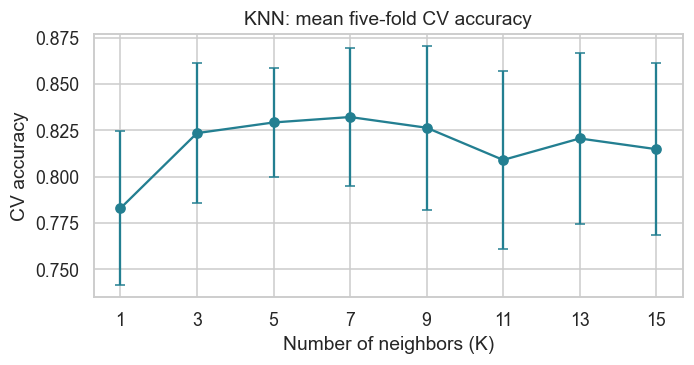

In [4]:
knnRows = []
for kValue in range(1, 16, 2):
    knnPipeline = make_pipeline(
        clone(preprocessor), StandardScaler(), KNeighborsClassifier(n_neighbors=kValue)
    )
    foldScores = cross_val_score(
        knnPipeline, trainInputs, trainTarget, cv=cvFolds, scoring="accuracy"
    )
    knnRows.append({"K": kValue, "CV mean": foldScores.mean(), "CV std": foldScores.std()})
knnResults = pd.DataFrame(knnRows)
bestK = int(knnResults.loc[knnResults["CV mean"].idxmax(), "K"])
display(knnResults.round(4))
print("Chosen K:", bestK)
knnResults.to_csv(outputDir / "knn_tuning.csv", index=False)

plt.figure(figsize=(6.4, 3.5))
plt.errorbar(knnResults["K"], knnResults["CV mean"], yerr=knnResults["CV std"],
             marker="o", capsize=3, color="#237F91")
plt.xticks(list(range(1, 16, 2)))
plt.title("KNN: mean five-fold CV accuracy")
plt.xlabel("Number of neighbors (K)")
plt.ylabel("CV accuracy")
plt.tight_layout()
plt.savefig(outputDir / "knn_cv_curve.png", dpi=180)
plt.show()
plt.close()

### Tree depth
A deeper tree can fit more detail, including noise. `None` allows an
unrestricted maximum depth, subject to the tree's other stopping rules.
The CV curve shows whether that flexibility helps on held-out folds.

,maxDepth,CV mean,CV std
0,2,0.6875,0.0204
1,3,0.7324,0.0498
2,5,0.7801,0.0526
3,10,0.7859,0.0332
4,None,0.7801,0.0325


Chosen max_depth: 10


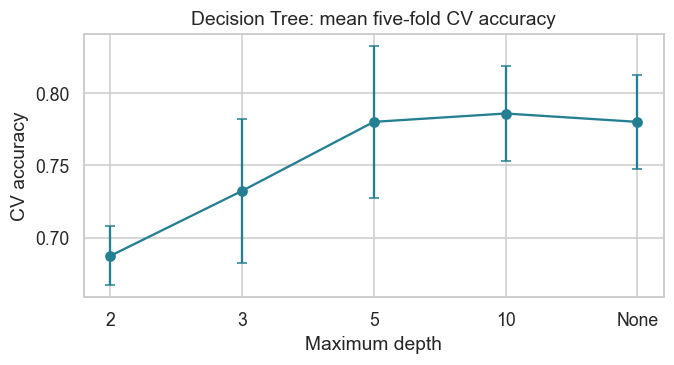

In [5]:
depthValues = [2, 3, 5, 10, None]
treeRows = []
for depthValue in depthValues:
    treePipeline = make_pipeline(
        clone(preprocessor), DecisionTreeClassifier(max_depth=depthValue, random_state=42)
    )
    foldScores = cross_val_score(
        treePipeline, trainInputs, trainTarget, cv=cvFolds, scoring="accuracy"
    )
    treeRows.append({
        "maxDepth": str(depthValue), "CV mean": foldScores.mean(), "CV std": foldScores.std()
    })
treeResults = pd.DataFrame(treeRows)
bestDepth = depthValues[treeResults["CV mean"].idxmax()]
display(treeResults.round(4))
print("Chosen max_depth:", bestDepth)
treeResults.to_csv(outputDir / "tree_tuning.csv", index=False)

plt.figure(figsize=(6.4, 3.5))
plt.errorbar(treeResults["maxDepth"], treeResults["CV mean"], yerr=treeResults["CV std"],
             marker="o", capsize=3, color="#237F91")
plt.title("Decision Tree: mean five-fold CV accuracy")
plt.xlabel("Maximum depth")
plt.ylabel("CV accuracy")
plt.tight_layout()
plt.savefig(outputDir / "tree_cv_curve.png", dpi=180)
plt.show()
plt.close()

## Step 4: Tune Random Forest with GridSearchCV
The required grid has 3 choices for `n_estimators` and 3 choices for
`max_depth`: **9 combinations x 5 folds = 45 CV trainings**.
`GridSearchCV` then refits the best configuration once on all training
rows, so the search performs 46 fits including that refit.

The parameter names include the pipeline step name. For example,
`randomforestclassifier__n_estimators` sets the forest's tree count.
The final test set is still unused.

In [6]:
forestGrid = {
    "randomforestclassifier__n_estimators": [50, 100, 200],
    "randomforestclassifier__max_depth": [3, 5, None]
}
forestSearch = GridSearchCV(
    baseModels["Random Forest"], forestGrid, cv=cvFolds, scoring="accuracy",
    n_jobs=1, error_score="raise"
)
forestSearch.fit(trainInputs, trainTarget)
print("Random Forest best_params_:", forestSearch.best_params_)
print("Random Forest best_score_:", forestSearch.best_score_)
print("CV trainings:", len(forestSearch.cv_results_["params"]) * cvFolds.get_n_splits())
print("Additional best-model refit: 1")
pd.DataFrame(forestSearch.cv_results_).to_csv(outputDir / "random_forest_grid.csv", index=False)

Random Forest best_params_: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 100}
Random Forest best_score_: 0.836544677301637
CV trainings: 45
Additional best-model refit: 1


### Tune Gradient Boosting and compare it with Random Forest
I also search `learning_rate` = 0.05, 0.1, 0.2 and `n_estimators` =
50, 100, 200. This is another 9 combinations and 45 CV trainings, plus
one best-model refit. All other settings stay at their defaults, with
`random_state=42`.

A lower learning rate makes each added tree contribute less. The tree
count determines how many boosting stages are fitted. I compare the
searches using the same folds and accuracy score, not final test scores.

Gradient Boosting best_params_: {'gradientboostingclassifier__learning_rate': 0.05, 'gradientboostingclassifier__n_estimators': 200}
Gradient Boosting best_score_: 0.8524867062871442
CV trainings: 45
Additional best-model refit: 1


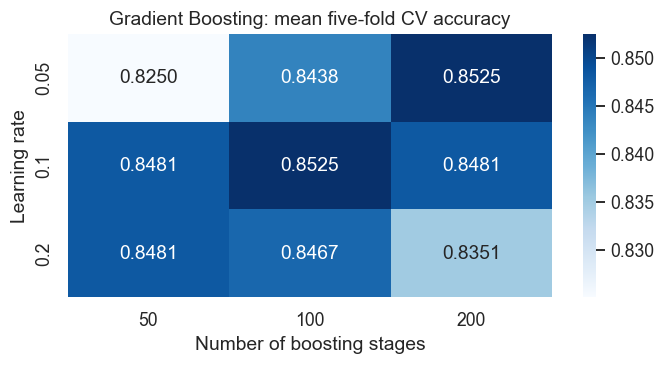

In [7]:
boostingGrid = {
    "gradientboostingclassifier__learning_rate": [0.05, 0.1, 0.2],
    "gradientboostingclassifier__n_estimators": [50, 100, 200]
}
boostingSearch = GridSearchCV(
    baseModels["Gradient Boosting"], boostingGrid, cv=cvFolds, scoring="accuracy",
    n_jobs=1, error_score="raise"
)
boostingSearch.fit(trainInputs, trainTarget)
print("Gradient Boosting best_params_:", boostingSearch.best_params_)
print("Gradient Boosting best_score_:", boostingSearch.best_score_)
print("CV trainings:", len(boostingSearch.cv_results_["params"]) * cvFolds.get_n_splits())
print("Additional best-model refit: 1")
boostingGridResults = pd.DataFrame(boostingSearch.cv_results_)
boostingGridResults.to_csv(outputDir / "gradient_boosting_grid.csv", index=False)

boostingPlot = boostingGridResults.pivot(
    index="param_gradientboostingclassifier__learning_rate",
    columns="param_gradientboostingclassifier__n_estimators", values="mean_test_score"
)
plt.figure(figsize=(6.4, 3.5))
sns.heatmap(boostingPlot, annot=True, fmt=".4f", cmap="Blues")
plt.title("Gradient Boosting: mean five-fold CV accuracy")
plt.xlabel("Number of boosting stages")
plt.ylabel("Learning rate")
plt.tight_layout()
plt.savefig(outputDir / "gradient_boosting_grid.png", dpi=180)
plt.show()
plt.close()

## Step 5: Check for overfitting without opening the final test set
In the table below, **Test score means the held-out CV fold score**
inside the 80% training data. This is the `test_score` returned by
scikit-learn cross-validation. It is not the final 20% test set.
This resolves the task's request for a train/test gap while keeping the
final test set unused until Step 6.

I compare the four chosen configurations on the same five folds.
The gap is mean fold training accuracy minus mean fold validation
accuracy. A larger gap suggests more overfitting. A smaller CV standard
deviation indicates more consistent scores across these folds; it is
a different measure from the training-validation gap.

In [8]:
tunedModels = {
    "KNN": make_pipeline(clone(preprocessor), StandardScaler(), KNeighborsClassifier(n_neighbors=bestK)),
    "Decision Tree": make_pipeline(clone(preprocessor), DecisionTreeClassifier(max_depth=bestDepth, random_state=42)),
    "Random Forest": forestSearch.best_estimator_,
    "Gradient Boosting": boostingSearch.best_estimator_
}
overfittingRows = []
tunedRows = []
for modelName, modelPipeline in tunedModels.items():
    foldResults = cross_validate(
        modelPipeline, trainInputs, trainTarget, cv=cvFolds,
        scoring="accuracy", return_train_score=True
    )
    trainMean = foldResults["train_score"].mean()
    validationMean = foldResults["test_score"].mean()
    validationStd = foldResults["test_score"].std()
    overfittingRows.append({
        "Model": modelName, "Train score": trainMean,
        "Test score": validationMean, "Gap": trainMean - validationMean
    })
    tunedRows.append({"Model": modelName, "CV mean": validationMean, "CV std": validationStd})
overfittingTable = pd.DataFrame(overfittingRows)
tunedResults = pd.DataFrame(tunedRows)
display(overfittingTable.round(4))
display(tunedResults.round(4))
overfittingTable.to_csv(outputDir / "overfitting_cv_gaps.csv", index=False)
tunedResults.to_csv(outputDir / "tuned_cv_results.csv", index=False)

mostOverfitModel = overfittingTable.loc[overfittingTable["Gap"].idxmax(), "Model"]
mostStableModel = tunedResults.loc[tunedResults["CV std"].idxmin(), "Model"]
rankedModels = tunedResults.sort_values(["CV mean", "CV std"], ascending=[False, True], kind="stable")
bestModelName = rankedModels.iloc[0]["Model"]
print("Largest training-validation gap:", mostOverfitModel)
print("Smallest variation across CV folds:", mostStableModel)
print("Model selected before the final test:", bestModelName)
print("Selection rule: highest CV mean; a tie favors lower CV standard deviation.")

,Model,Train score,Test score,Gap
0,KNN,0.8763,0.8322,0.0441
1,Decision Tree,0.9935,0.7859,0.2076
2,Random Forest,1.0000,0.8365,0.1635
3,Gradient Boosting,0.9996,0.8525,0.1472


,Model,CV mean,CV std
0,KNN,0.8322,0.0372
1,Decision Tree,0.7859,0.0332
2,Random Forest,0.8365,0.0364
3,Gradient Boosting,0.8525,0.0368


Largest training-validation gap: Decision Tree
Smallest variation across CV folds: Decision Tree
Model selected before the final test: Gradient Boosting
Selection rule: highest CV mean; a tie favors lower CV standard deviation.


### What the training-only comparison shows

- **KNN:** I chose **K = 7** because its mean CV accuracy was 83.22%,
  the highest among the tested odd values.
- **Decision Tree:** I chose **max_depth = 10**, with 78.59%
  mean CV accuracy. Allowing unlimited depth did not improve the CV score.
- **Random Forest:** The search chose **100 trees and no maximum depth**,
  scoring 83.65%. This is also the baseline forest's setting,
  so tuning did not improve its mean accuracy.
- **Gradient Boosting:** The search chose **learning_rate = 0.05 and
  n_estimators = 200**, scoring 85.25%. This is the highest tuned
  mean, so I select it before opening the final test set.

Gradient Boosting leads Random Forest by
1.59 percentage points in mean CV accuracy.
Their fold scores still vary, so this is not proof of a universal advantage.
Boosting's tuned mean is also essentially unchanged from its default baseline
of 85.25%. The search found a setting, not a large performance jump.

**Overfitting:** The tuned Decision Tree has the largest gap,
0.2076. KNN has the smallest gap,
0.0441, so it shows the least separation between training and CV accuracy here.

**Stability:** The tree has the smallest CV standard deviation,
0.0332. Its fold scores are more consistent, but consistently
lower than the stronger models. Low variation does not cancel its large
training-validation gap or make it the best model.


## Step 6: Final test and decision
The winning model and its settings are now fixed using training-data
CV only. I fit a fresh copy on all 691 training players, then call
`predict` **once** on the 173 held-out players. Accuracy, the confusion
matrix, and the classification report all use this same prediction array.
I do not compare or retune other models using these final test results.

For a position-based shortlist, I would prioritize **precision**: a
player recommended as a forward should actually belong to the recorded
forward group. I still inspect recall so missed forwards are visible,
and the report shows both metrics for every role. This is an assumed
use case for game data, not a claim about real scouting decisions.

Selected model: Gradient Boosting
Final test accuracy: 0.8439306358381503
              precision    recall  f1-score   support

    Defender     0.8710    0.9474    0.9076        57
  Midfielder     0.8429    0.7867    0.8138        75
     Forward     0.8049    0.8049    0.8049        41

    accuracy                         0.8439       173
   macro avg     0.8396    0.8463    0.8421       173
weighted avg     0.8431    0.8439    0.8426       173

Processed shapes: (691, 11) (173, 11)
All processed input values are finite. Fills were learned from training data only.


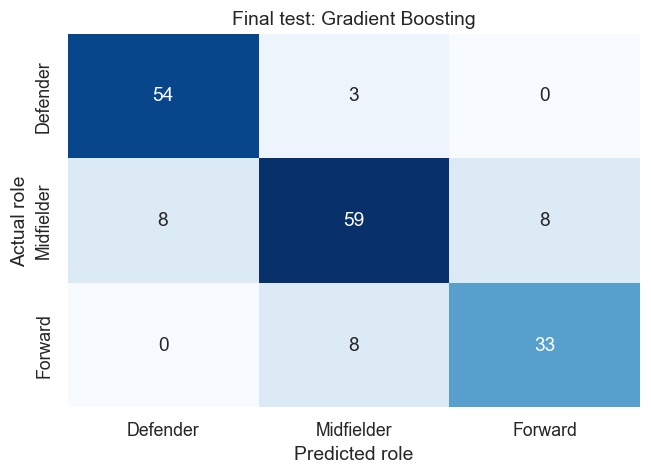

,sofifa_id,short_name,firstPosition,actualRole,predictedRole
883,261349,L. Cingolani,RW,Forward,Midfielder
914,258087,G. Gozálvez,LM,Midfielder,Forward
169,227785,C. Guanca,CAM,Midfielder,Forward
957,261501,F. Torres,RM,Midfielder,Forward
838,261438,S. Rosane,CDM,Midfielder,Defender
894,214666,F. Vázquez,CM,Midfielder,Defender
94,188268,L. Acosta,LW,Forward,Midfielder
920,259270,R. Luna,RW,Forward,Midfielder
710,253715,D. Sarmiento,LM,Midfielder,Forward
425,186553,M. Rodríguez,RB,Defender,Midfielder


In [9]:
finalModel = clone(tunedModels[bestModelName])
finalModel.fit(trainInputs, trainTarget)
finalPredictions = finalModel.predict(testInputs)

testAccuracy = accuracy_score(testTarget, finalPredictions)
finalMatrix = confusion_matrix(testTarget, finalPredictions, labels=classOrder)
reportText = classification_report(
    testTarget, finalPredictions, labels=classOrder, digits=4, zero_division=0
)
print("Selected model:", bestModelName)
print("Final test accuracy:", testAccuracy)
print(reportText)
(outputDir / "final_classification_report.txt").write_text(reportText, encoding="utf-8")
reportValues = classification_report(
    testTarget, finalPredictions, labels=classOrder, output_dict=True, zero_division=0
)
reportValues.pop("accuracy")
pd.DataFrame(reportValues).T.to_csv(outputDir / "final_classification_report.csv", index_label="class")
pd.DataFrame([{"Model": bestModelName, "Test accuracy": testAccuracy}]).to_csv(
    outputDir / "final_test_result.csv", index=False
)

fittedPreprocessor = finalModel.named_steps["columntransformer"]
processedTrain = fittedPreprocessor.transform(trainInputs)
processedTest = fittedPreprocessor.transform(testInputs)
assert np.isfinite(processedTrain).all() and np.isfinite(processedTest).all()
np.testing.assert_allclose(
    fittedPreprocessor.named_transformers_["numeric"].statistics_, trainInputs[numericColumns].median()
)
assert processedTrain.shape[1] == processedTest.shape[1]
print("Processed shapes:", processedTrain.shape, processedTest.shape)
print("All processed input values are finite. Fills were learned from training data only.")

plt.figure(figsize=(6.1, 4.5))
sns.heatmap(finalMatrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=classOrder, yticklabels=classOrder)
plt.title(f"Final test: {bestModelName}")
plt.xlabel("Predicted role")
plt.ylabel("Actual role")
plt.tight_layout()
plt.savefig(outputDir / "final_confusion_matrix.png", dpi=180)
plt.show()
plt.close()

predictionDetails = playerData.loc[testInputs.index, ["sofifa_id", "short_name", "firstPosition"]].copy()
predictionDetails["actualRole"] = testTarget
predictionDetails["predictedRole"] = finalPredictions
predictionDetails.to_csv(outputDir / "final_test_predictions.csv", index_label="sourceRow")
display(predictionDetails[predictionDetails["actualRole"] != predictionDetails["predictedRole"]].head(10))

### Final decision and error interpretation

I keep **Gradient Boosting**, selected by training-only CV. Its final test
accuracy is **84.39%**, with **27 mistakes among 173 players**.
The macro F1-score is **0.8421**. I do not use this result
to change the model, its parameters, or the role definitions.

The model correctly identified **54 of 57 defenders**, **59 of 75 midfielders**,
and **33 of 41 forwards**. It confused eight forwards with midfielders and
eight midfielders with forwards. Those neighboring role groups can share
similar skills, especially when the first-listed position is a wide role.
This is a possible explanation, not a measured cause of the errors.

For a forward shortlist, precision matters because inaccurate suggestions
make the shortlist less useful. Forward precision is
**80.49%**: 33 of the 41 predicted forwards match the recorded group.
Forward recall is also **80.49%**, so eight actual forwards were missed.
Both metrics matter; prioritizing precision is the stated use-case preference.


## What these results can tell us
Cross-validation provides a more useful comparison than choosing settings
from one lucky split. I used the same five folds for every candidate,
and preprocessing stayed inside each fold. The selected CV score can
still be optimistic because it was also used to choose settings; the
separate final test is the independent check.

The role groups simplify multi-position players into one category. A
winger listed as LM is grouped as a midfielder, while LW is grouped as
a forward, so some boundaries are naturally close. Skill ratings and
positions also come from the same video-game database. Good results
here do not show future match performance or suitability for real scouting.

This experiment covers Argentinian male outfield players in one historical
FIFA edition. A different nationality, season, or source may behave differently.

**Sources:** [FIFA 22 dataset](https://www.kaggle.com/datasets/stefanoleone992/fifa-22-complete-player-dataset),
[scikit-learn cross-validation](https://scikit-learn.org/1.8/modules/cross_validation.html),
[GridSearchCV](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GridSearchCV.html).